<a href="https://colab.research.google.com/github/agugun/axscnt-notebook/blob/main/Vector_Calculus_Basic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

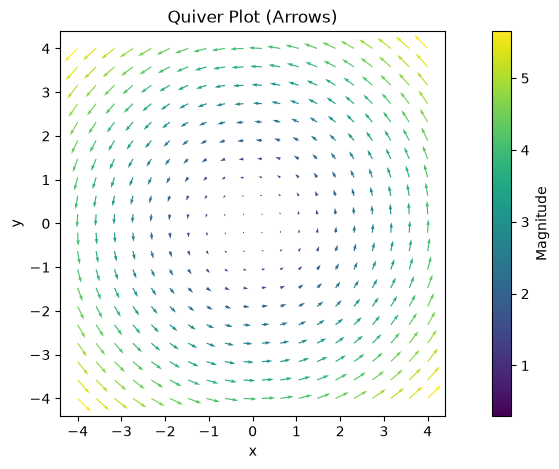

In [ ]:
# basic vector field. generate mesh grid and showing using uiver plot with magnitude.
# implement also matrix parameterization which u and v use x and y as parameter.

import matplotlib.pyplot as plt
import numpy as np

# Create a 20x20 grid
x = np.linspace(-4, 4, 20)
y = np.linspace(-4, 4, 20)
X, Y = np.meshgrid(x, y)

# Define vector field: F(x, y) = (-y, x)
U = -Y
V = X

# Calculate vector magnitude for color mapping
magnitude = np.hypot(U, V)

plt.figure(figsize=(12, 5))

# Quiver Plot (Arrows)
q = plt.quiver(X, Y, U, V, magnitude, cmap='viridis')
plt.title('Quiver Plot (Arrows)')
plt.xlabel('x')
plt.ylabel('y')
plt.gca().set_aspect('equal')
plt.colorbar(q, label='Magnitude')

plt.show()

In [10]:
# Connect gradient with line integrals: The Fundamental Theorem of Line Integrals
# Using Plotly for a highly interactive, responsive 3D visualization in Colab!

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Define the 2D grid and scalar potential field Z (Gaussian Hill)
x_vals = np.linspace(-3, 3, 40)
y_vals = np.linspace(-3, 3, 40)
X, Y = np.meshgrid(x_vals, y_vals)
Z = np.exp(-(X**2 + Y**2) / 2.0)

# Compute numerical gradient
dZ_dy, dZ_dx = np.gradient(Z, y_vals, x_vals)

# 2. Define a curved parameterized path r(t) = (x(t), y(t))
t = np.linspace(0, 1, 200)
path_x = -2.0 * (1 - t) + 1.5 * t + 0.5 * np.sin(np.pi * t)
path_y = -1.5 * (1 - t) + 1.5 * t - 0.5 * np.sin(np.pi * t)

# Calculate derivatives and evaluate line integral
dt = t[1] - t[0]
dx_dt = np.gradient(path_x, dt)
dy_dt = np.gradient(path_y, dt)
path_Z = np.exp(-(path_x**2 + path_y**2) / 2.0)
path_grad_x = -path_x * path_Z
path_grad_y = -path_y * path_Z

integrand = path_grad_x * dx_dt + path_grad_y * dy_dt
trapezoid_func = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
if trapezoid_func is not None:
    line_integral = trapezoid_func(integrand, t)
else:
    line_integral = np.sum((integrand[:-1] + integrand[1:]) / 2.0) * dt

Z_A = path_Z[0]
Z_B = path_Z[-1]
potential_difference = Z_B - Z_A

print("--- VERIFYING THE FUNDAMENTAL THEOREM OF LINE INTEGRALS ---")
print(f"Start Point A: ({path_x[0]:.2f}, {path_y[0]:.2f}) -> Z(A) = {Z_A:.6f}")
print(f"End Point B:   ({path_x[-1]:.2f}, {path_y[-1]:.2f}) -> Z(B) = {Z_B:.6f}")
print(f"Direct Potential Difference Z(B) - Z(A): {potential_difference:.6f}")
print(f"Line Integral of Gradient field:        {line_integral:.6f}")
print(f"Absolute error:                         {abs(line_integral - potential_difference):.2e}")
print("-----------------------------------------------------------")

# 3. Build Interactive Plotly Figure with Side-by-Side Plots
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'scene'}, {'type': 'xy'}]],
    subplot_titles=("Interactive 3D Surface & Complete Vector Field", "2D Contour Projection & Path C")
)

# --- Left: Interactive 3D Plot (Surface + Complete Vector Field + Path) ---
# Add the 3D surface
fig.add_trace(
    go.Surface(x=X, y=Y, z=Z, colorscale='Viridis', opacity=0.75, showscale=False, name="Z(x, y)"),
    row=1, col=1
)

# Add path line
fig.add_trace(
    go.Scatter3d(x=path_x, y=path_y, z=path_Z, mode='lines',
                 line=dict(color='red', width=7), name="Path C"),
    row=1, col=1
)

# Add start and end points
fig.add_trace(
    go.Scatter3d(x=[path_x[0]], y=[path_y[0]], z=[Z_A], mode='markers',
                 marker=dict(size=8, color='blue', symbol='circle'), name="Start A"),
    row=1, col=1
)
fig.add_trace(
    go.Scatter3d(x=[path_x[-1]], y=[path_y[-1]], z=[Z_B], mode='markers',
                 marker=dict(size=8, color='orange', symbol='circle'), name="End B"),
    row=1, col=1
)

# Create downsampled 3D Vector arrows using Cone traces
step_field = 3
X_f, Y_f, Z_f = X[::step_field, ::step_field].flatten(), Y[::step_field, ::step_field].flatten(), Z[::step_field, ::step_field].flatten()
dZ_dx_f, dZ_dy_f = dZ_dx[::step_field, ::step_field].flatten(), dZ_dy[::step_field, ::step_field].flatten()

fig.add_trace(
    go.Cone(
        x=X_f,
        y=Y_f,
        z=Z_f + 0.02, # Slightly offset upward to avoid clipping
        u=dZ_dx_f,
        v=dZ_dy_f,
        w=np.zeros_like(Z_f),
        colorscale='electric', # Valid, vibrant named colorscale
        showscale=False,
        sizemode='scaled',
        sizeref=1.5,
        name="Grad Z Field"
    ),
    row=1, col=1
)

# --- Right: Interactive 2D Contour Plot with Quiver Overlay ---
fig.add_trace(
    go.Contour(x=x_vals, y=y_vals, z=Z, colorscale='Viridis', opacity=0.85, showscale=True, name="Contours"),
    row=1, col=2
)

fig.add_trace(
    go.Scatter(x=path_x, y=path_y, mode='lines', line=dict(color='red', width=4), name="Path C (2D)"),
    row=1, col=2
)

fig.add_trace(
    go.Scatter(x=[path_x[0]], y=[path_y[0]], mode='markers', marker=dict(size=12, color='blue'), name="Start A (2D)"),
    row=1, col=2
)
fig.add_trace(
    go.Scatter(x=[path_x[-1]], y=[path_y[-1]], mode='markers', marker=dict(size=12, color='orange'), name="End B (2D)"),
    row=1, col=2
)

# Update Layout to ensure responsive interaction
fig.update_layout(
    title="Interactive Vector Fields & Fundamental Theorem of Line Integrals",
    title_font=dict(size=16, family="Arial", color="white"),
    template='plotly_dark',
    width=1300,
    height=650,
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.2))
    ),
    xaxis2=dict(title='X', scaleanchor='y', scaleratio=1),
    yaxis2=dict(title='Y'),
    margin=dict(l=20, r=20, t=80, b=20)
)

fig.show()

--- VERIFYING THE FUNDAMENTAL THEOREM OF LINE INTEGRALS ---
Start Point A: (-2.00, -1.50) -> Z(A) = 0.043937
End Point B:   (1.50, 1.50) -> Z(B) = 0.105399
Direct Potential Difference Z(B) - Z(A): 0.061462
Line Integral of Gradient field:        0.061464
Absolute error:                         1.64e-06
-----------------------------------------------------------


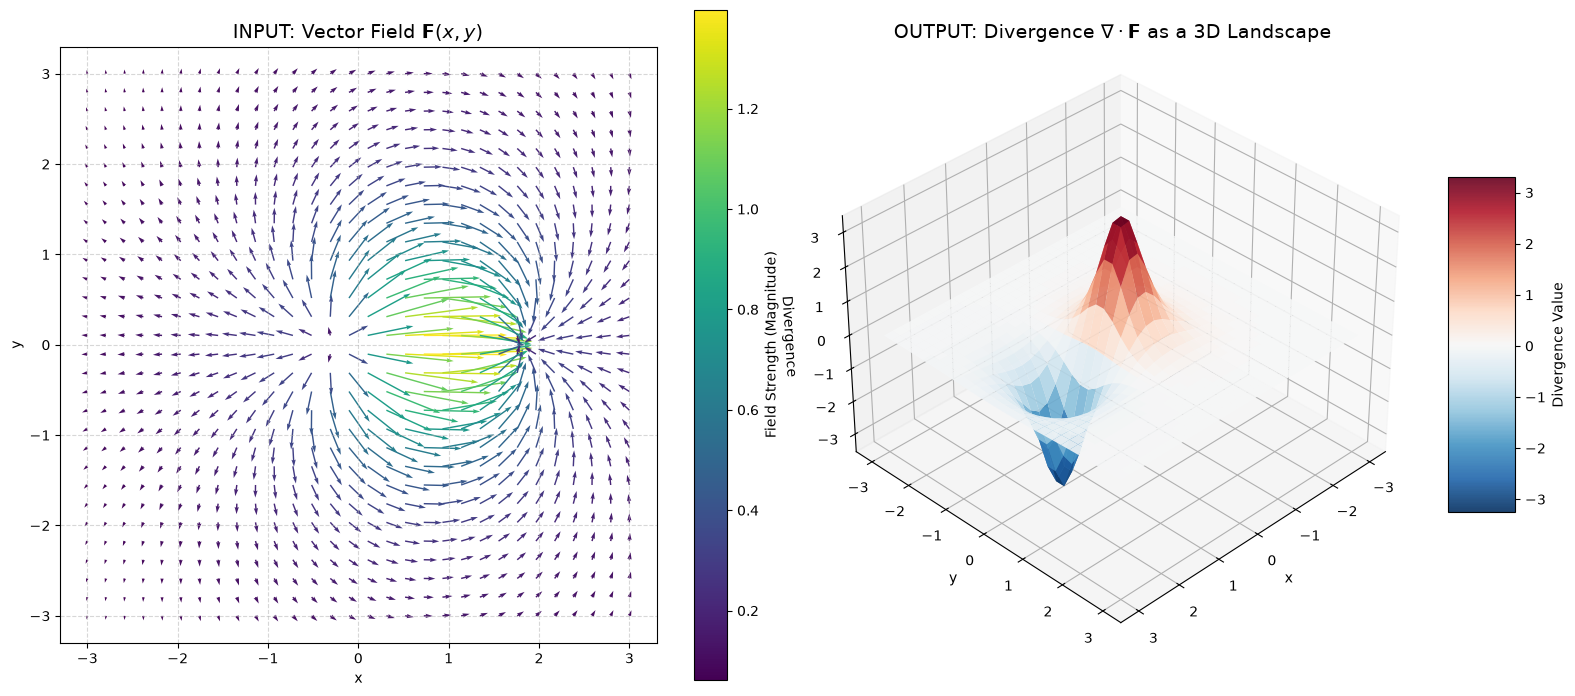

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Setup a 2D grid
x = np.linspace(-3, 3, 30)
y = np.linspace(-3, 3, 30)
X, Y = np.meshgrid(x, y)

# 2. Define an input vector field with clear sources and sinks
U = X / (X**2 + Y**2 + 0.5) - (X - 1.5) / ((X - 1.5)**2 + Y**2 + 0.5)
V = Y / (X**2 + Y**2 + 0.5) - Y / ((X - 1.5)**2 + Y**2 + 0.5)

# 3. Calculate the resulting scalar field (Divergence)
dU_dy, dU_dx = np.gradient(U, y, x)
dV_dy, dV_dx = np.gradient(V, y, x)
divergence_scalar = dU_dx + dV_dy

# 4. Create side-by-side plots
fig = plt.figure(figsize=(16, 7))

# --- Left Plot: INPUT (2D Vector Field) ---
ax1 = fig.add_subplot(1, 2, 1)
magnitude = np.hypot(U, V)
quiv = ax1.quiver(X, Y, U, V, magnitude, cmap='viridis', scale=10)
fig.colorbar(quiv, ax=ax1, label='Field Strength (Magnitude)')
ax1.set_title('INPUT: Vector Field $\\mathbf{F}(x, y)$', fontsize=14)
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_aspect('equal')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Right Plot: OUTPUT (3D Divergence Scalar Field) ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf = ax2.plot_surface(X, Y, divergence_scalar, cmap='RdBu_r', edgecolor='none', alpha=0.9)
fig.colorbar(surf, ax=ax2, shrink=0.5, aspect=5, label='Divergence Value')
ax2.set_title('OUTPUT: Divergence $\\nabla \\cdot \\mathbf{F}$ as a 3D Landscape', fontsize=14)
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('Divergence')
ax2.view_init(elev=35, azim=45)

plt.tight_layout()
plt.show()

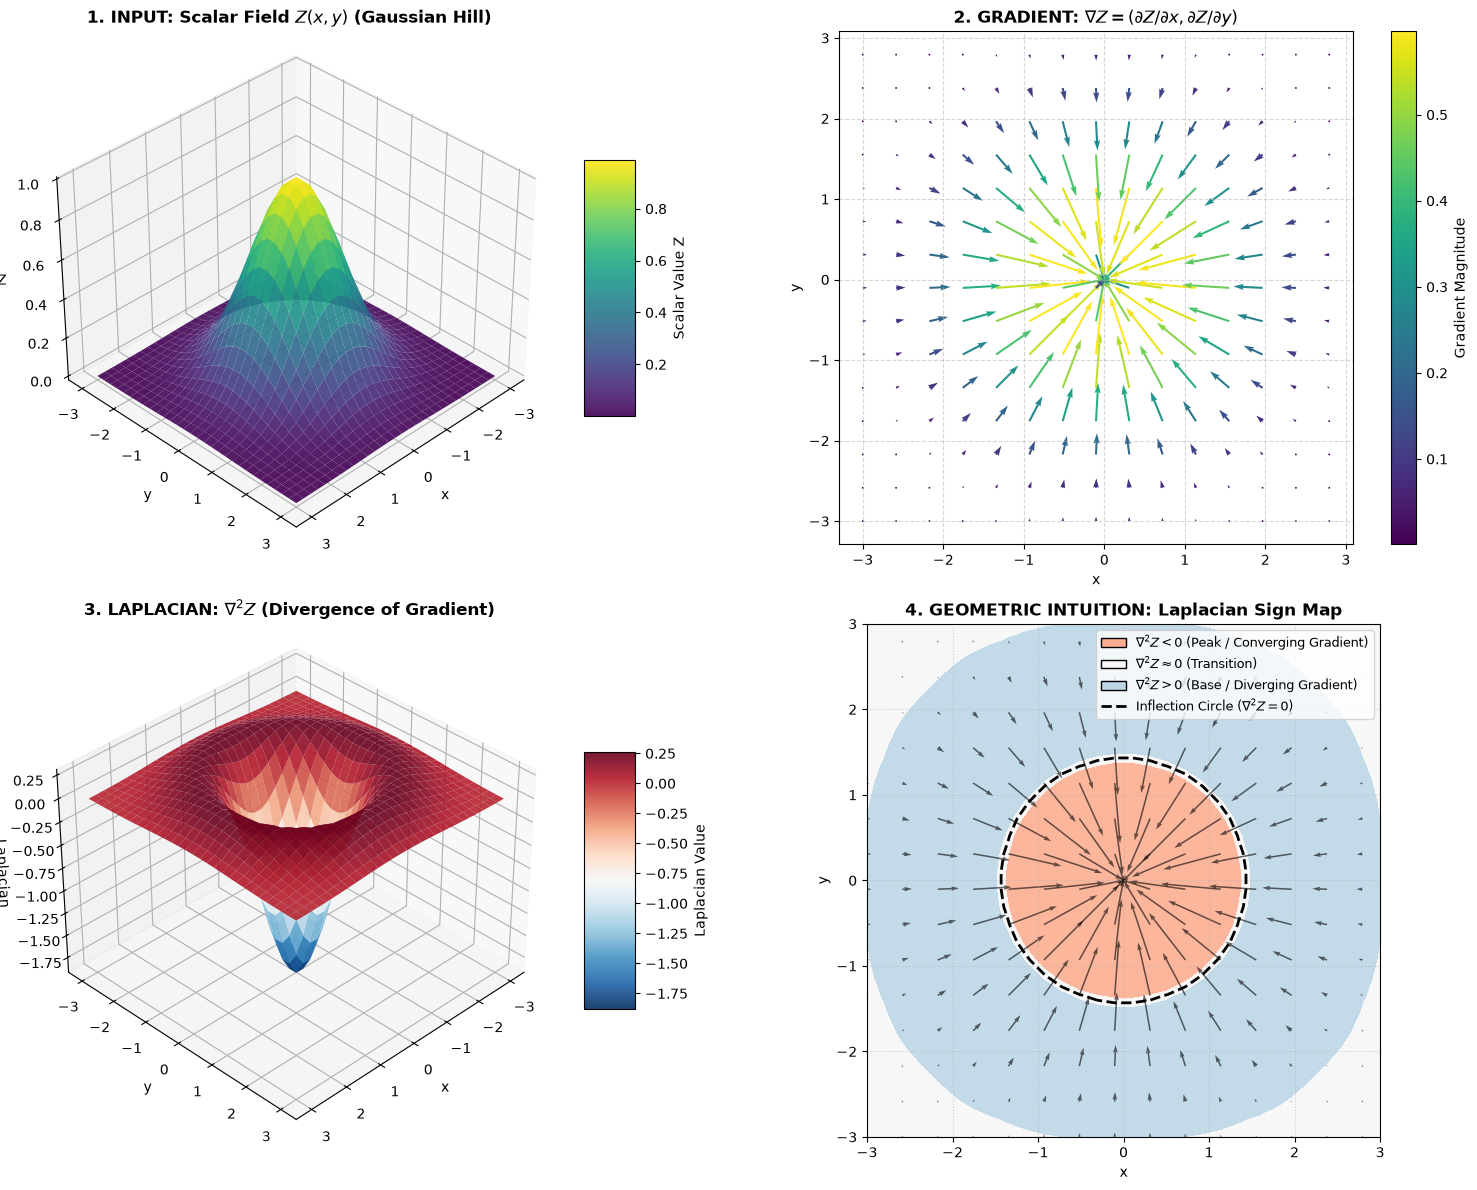

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Patch

# 1. Optimized Grid Resolution (30x30 for much faster rendering)
x = np.linspace(-3, 3, 30)
y = np.linspace(-3, 3, 30)
X, Y = np.meshgrid(x, y)

# 2. Define the input scalar field Z (Gaussian hill)
Z = np.exp(-(X**2 + Y**2) / 2.0)

# 3. Compute the gradient components (first derivatives)
dZ_dy, dZ_dx = np.gradient(Z, y, x)

# 4. Compute the divergence of the gradient (second derivatives to get Laplacian)
_, d2Z_dx2 = np.gradient(dZ_dx, y, x)
d2Z_dy2, _ = np.gradient(dZ_dy, y, x)
laplacian_scalar = d2Z_dx2 + d2Z_dy2

# 5. Create a 2x2 multi-panel visualization showing the complete step-by-step process
fig = plt.figure(figsize=(16, 12))

# --- Panel 1: INPUT (3D Scalar Potential Field) ---
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
surf1 = ax1.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.9)
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=5, label='Scalar Value Z')
ax1.set_title('1. INPUT: Scalar Field $Z(x, y)$ (Gaussian Hill)', fontsize=12, fontweight='bold')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('Z')
ax1.view_init(elev=35, azim=45)

# --- Panel 2: INTERMEDIATE (Gradient Vector Field) ---
ax2 = fig.add_subplot(2, 2, 2)
magnitude = np.hypot(dZ_dx, dZ_dy)
# Downsampled quiver arrows slightly for speed and clarity
quiv = ax2.quiver(X[::2, ::2], Y[::2, ::2], dZ_dx[::2, ::2], dZ_dy[::2, ::2],
                  magnitude[::2, ::2], cmap='viridis', scale=5)
fig.colorbar(quiv, ax=ax2, label='Gradient Magnitude')
ax2.set_title('2. GRADIENT: $\\nabla Z = (\\partial Z/\\partial x, \\partial Z/\\partial y)$', fontsize=12, fontweight='bold')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_aspect('equal')
ax2.grid(True, linestyle='--', alpha=0.5)

# --- Panel 3: OUTPUT (3D Laplacian Scalar Field) ---
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
surf2 = ax3.plot_surface(X, Y, laplacian_scalar, cmap='RdBu_r', edgecolor='none', alpha=0.9)
fig.colorbar(surf2, ax=ax3, shrink=0.5, aspect=5, label='Laplacian Value')
ax3.set_title('3. LAPLACIAN: $\\nabla^2 Z$ (Divergence of Gradient)', fontsize=12, fontweight='bold')
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_zlabel('Laplacian')
ax3.view_init(elev=35, azim=45)

# --- Panel 4: GEOMETRIC INTUITION (Laplacian Sign Map & Gradient Overlay) ---
ax4 = fig.add_subplot(2, 2, 4)

# Segment the Laplacian to show concave down (red-ish), flat (white), and concave up (blue-ish) regions
contour = ax4.contourf(X, Y, laplacian_scalar, levels=[-np.inf, -0.05, 0.05, np.inf],
                       colors=['#fcae91', '#f7f7f7', '#bdd7e7'], alpha=0.9)

# Draw inflection circle boundary where Laplacian = 0
ax4.contour(X, Y, laplacian_scalar, levels=[0.0], colors='black', linewidths=2, linestyles='--')

# Overlay gradient vectors to show they flow OUT of blue (divergence/valley) and into red (convergence/peak)
ax4.quiver(X[::2, ::2], Y[::2, ::2], dZ_dx[::2, ::2], dZ_dy[::2, ::2],
           color='black', alpha=0.6, scale=5, width=0.003)

legend_elements = [
    Patch(facecolor='#fcae91', edgecolor='black', label='$\\nabla^2 Z < 0$ (Peak / Converging Gradient)'),
    Patch(facecolor='#f7f7f7', edgecolor='black', label='$\\nabla^2 Z \\approx 0$ (Transition)'),
    Patch(facecolor='#bdd7e7', edgecolor='black', label='$\\nabla^2 Z > 0$ (Base / Diverging Gradient)'),
    plt.Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Inflection Circle ($\\nabla^2 Z = 0$)')
]
ax4.legend(handles=legend_elements, loc='upper right', fontsize=9)
ax4.set_title('4. GEOMETRIC INTUITION: Laplacian Sign Map', fontsize=12, fontweight='bold')
ax4.set_xlabel('x')
ax4.set_ylabel('y')
ax4.set_aspect('equal')
ax4.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

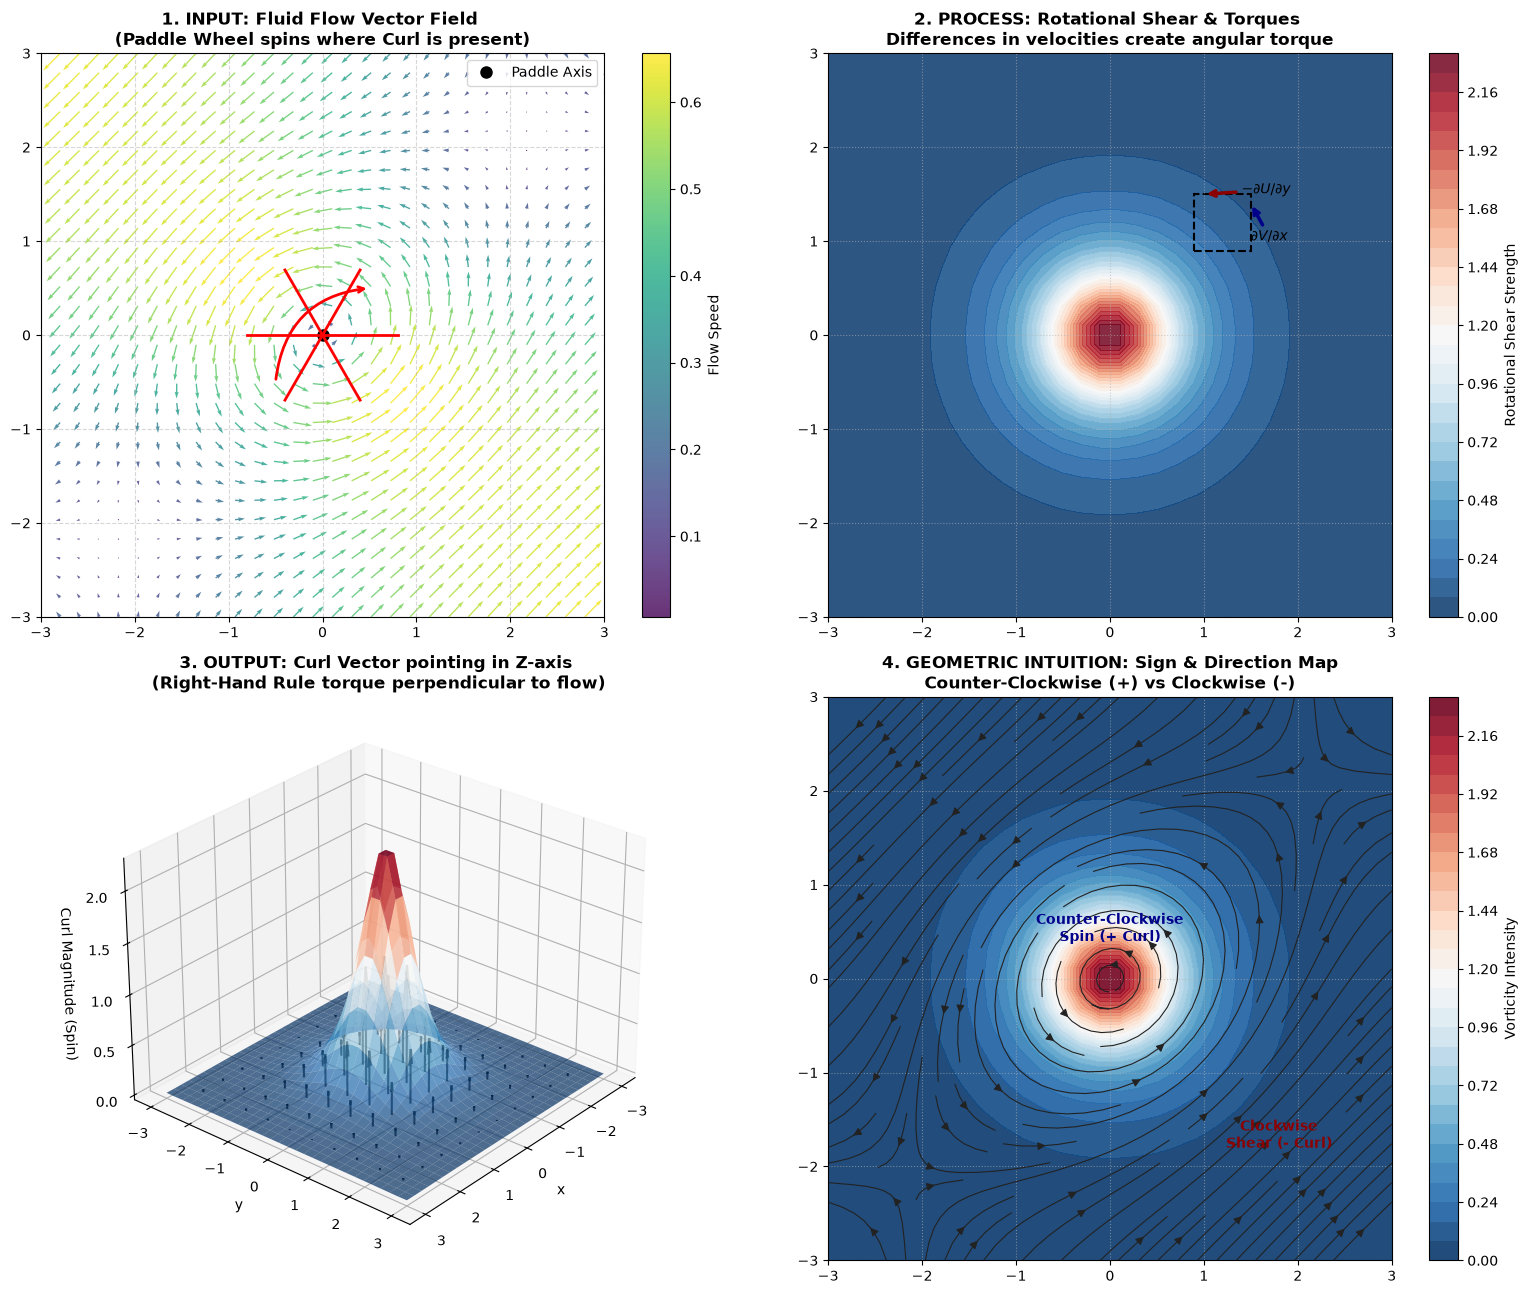

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Patch, FancyArrowPatch
from matplotlib.colors import Normalize

# 1. Setup high-quality grid
x = np.linspace(-3, 3, 30)
y = np.linspace(-3, 3, 30)
X, Y = np.meshgrid(x, y)

# 2. Define a combined vector field containing both a Vortex (CCW) and a Shear Flow (CW)
# This provides a rich palette to demonstrate both positive and negative Curl!
U = -Y / (X**2 + Y**2 + 0.8) + 0.1 * X
V = X / (X**2 + Y**2 + 0.8) - 0.1 * Y

# 3. Compute Curl components
dU_dy, dU_dx = np.gradient(U, y, x)
dV_dy, dV_dx = np.gradient(V, y, x)
curl_scalar = dV_dx - dU_dy

# Create a polished 2x2 layout illustrating: Input -> Process -> Output -> Intuition
fig = plt.figure(figsize=(16, 13))
colormap = plt.cm.RdBu_r

# --- Panel 1: INPUT (Vector Field with a Schematic Paddle Wheel) ---
ax1 = fig.add_subplot(2, 2, 1)
magnitude = np.hypot(U, V)
quiv = ax1.quiver(X, Y, U, V, magnitude, cmap='viridis', scale=15, alpha=0.8)
fig.colorbar(quiv, ax=ax1, label='Flow Speed')

# Draw a schematic paddle wheel to explain the physical test of curl
wheel_center = (0.0, 0.0)
ax1.plot(wheel_center[0], wheel_center[1], 'ko', markersize=8, label='Paddle Axis')
for angle in np.linspace(0, 2*np.pi, 6, endpoint=False):
    ax1.plot([wheel_center[0], wheel_center[0] + 0.8*np.cos(angle)],
             [wheel_center[1], wheel_center[1] + 0.8*np.sin(angle)],
             color='red', linewidth=2, zorder=5)
# Circular arrow representing rotation
ax1.annotate('', xy=(0.5, 0.5), xytext=(-0.5, -0.5),
             arrowprops=dict(arrowstyle="->", color="red", lw=2, connectionstyle="arc3,rad=-0.4"))

ax1.legend(loc='upper right')
ax1.set_title('1. INPUT: Fluid Flow Vector Field \n(Paddle Wheel spins where Curl is present)', fontsize=12, fontweight='bold')
ax1.set_xlim(-3, 3)
ax1.set_ylim(-3, 3)
ax1.set_aspect('equal')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Panel 2: PROCESS (Velocity Shear Gradient Interaction) ---
ax2 = fig.add_subplot(2, 2, 2)
# Show dV/dx - dU/dy contour gradient
contour_process = ax2.contourf(X, Y, curl_scalar, levels=30, cmap='RdBu_r', alpha=0.85)
fig.colorbar(contour_process, ax=ax2, label='Rotational Shear Strength')

# Overlay schematic differential rotation components
# Draw a microscopic fluid parcel at (1.5, 1.5)
parcel_x, parcel_y = 1.2, 1.2
ax2.add_patch(plt.Rectangle((parcel_x-0.3, parcel_y-0.3), 0.6, 0.6, fill=False, edgecolor='black', lw=1.5, ls='--'))
ax2.annotate('$\\partial V / \\partial x$', xy=(parcel_x+0.3, parcel_y+0.2), xytext=(parcel_x+0.3, parcel_y-0.2),
             arrowprops=dict(arrowstyle="->", color='darkblue', lw=2.5))
ax2.annotate('$-\\partial U / \\partial y$', xy=(parcel_x-0.2, parcel_y+0.3), xytext=(parcel_x+0.2, parcel_y+0.3),
             arrowprops=dict(arrowstyle="->", color='darkred', lw=2.5))

ax2.set_title('2. PROCESS: Rotational Shear & Torques \nDifferences in velocities create angular torque', fontsize=12, fontweight='bold')
ax2.set_xlim(-3, 3)
ax2.set_ylim(-3, 3)
ax2.set_aspect('equal')
ax2.grid(True, linestyle=':', alpha=0.6)

# --- Panel 3: OUTPUT (3D Torque Vector Axis) ---
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
surf = ax3.plot_surface(X, Y, curl_scalar, cmap='RdBu_r', edgecolor='none', alpha=0.7)

# Plot actual vertical curl torque vectors at coarser points
x_coarse = np.linspace(-2.5, 2.5, 10)
y_coarse = np.linspace(-2.5, 2.5, 10)
X_c, Y_c = np.meshgrid(x_coarse, y_coarse)
R2_c = X_c**2 + Y_c**2 + 0.8
U_c = -Y_c / R2_c + 0.1 * X_c
V_c = X_c / R2_c - 0.1 * Y_c
dU_dy_c, dU_dx_c = np.gradient(U_c, y_coarse, x_coarse)
dV_dy_c, dV_dx_c = np.gradient(V_c, y_coarse, x_coarse)
curl_z = dV_dx_c - dU_dy_c

# 3D Vector arrows representing Curl pointing upwards/downwards (z-axis)
ax3.quiver(X_c.flatten(), Y_c.flatten(), np.zeros_like(X_c).flatten(),
           np.zeros_like(X_c).flatten(), np.zeros_like(Y_c).flatten(), curl_z.flatten(),
           length=0.8, color='black', alpha=0.8, arrow_length_ratio=0.3)

ax3.set_title('3. OUTPUT: Curl Vector pointing in Z-axis \n(Right-Hand Rule torque perpendicular to flow)', fontsize=12, fontweight='bold')
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_zlabel('Curl Magnitude (Spin)')
ax3.view_init(elev=28, azim=40)

# --- Panel 4: GEOMETRIC INTUITION (Vorticity Direction Map) ---
ax4 = fig.add_subplot(2, 2, 4)
contour_int = ax4.contourf(X, Y, curl_scalar, levels=30, cmap='RdBu_r', alpha=0.9)
fig.colorbar(contour_int, ax=ax4, label='Vorticity Intensity')

# Overlay streamline traces to show actual flow trajectory relative to curl centers
ax4.streamplot(X, Y, U, V, color='#222222', density=1.0, linewidth=0.8, arrowsize=1.2)

# Explicit annotations for Rotation signs
ax4.text(0.0, 0.4, "Counter-Clockwise\nSpin (+ Curl)", color="darkblue", weight="bold", fontsize=10, ha="center")
ax4.text(1.8, -1.8, "Clockwise\nShear (- Curl)", color="darkred", weight="bold", fontsize=10, ha="center")

ax4.set_title('4. GEOMETRIC INTUITION: Sign & Direction Map\nCounter-Clockwise (+) vs Clockwise (-)', fontsize=12, fontweight='bold')
ax4.set_xlim(-3, 3)
ax4.set_ylim(-3, 3)
ax4.set_aspect('equal')
ax4.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# 1. Physical and Numerical Parameters
L = 10.0          # Length of the metal rod
T_max = 4.0       # Total simulation time
alpha = 1.2       # Thermal diffusivity coefficient

Nx = 80           # Number of spatial grid points
Nt = 500          # Number of time steps

dx = L / (Nx - 1)
dt = T_max / Nt

# Check stability condition for FTCS scheme (r <= 0.5)
r = alpha * dt / (dx**2)
if r > 0.5:
    print(f"Warning: The simulation might be unstable. r = {r:.4f} (should be <= 0.5). Adjusting dt...")
    dt = 0.5 * (dx**2) / alpha
    Nt = int(np.ceil(T_max / dt))
    r = alpha * dt / (dx**2)
    print(f"New time step size: {dt:.6f}, Total steps: {Nt}, r = {r:.4f}")

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

# 2. Initialize temperature grid U(x, t)
U = np.zeros((Nx, Nt))

# Initial Condition: A highly localized hot spot (Gaussian peak) in the middle
U[:, 0] = 100.0 * np.exp(-((x_grid - L/2)**2) / 1.5)

# Boundary Conditions (Dirichlet): Ends of the rod are kept in contact with ice (0 degrees)
U[0, :] = 0.0
U[-1, :] = 0.0

# 3. Finite Difference Solver (FTCS)
for t in range(0, Nt - 1):
    for i in range(1, Nx - 1):
        U[i, t+1] = U[i, t] + r * (U[i+1, t] - 2*U[i, t] + U[i-1, t])

print("Heat transfer equation solved successfully!")

implU = U.copy()

New time step size: 0.006676, Total steps: 600, r = 0.5000
Heat transfer equation solved successfully!


$$\frac{\partial U}{\partial t} = \alpha \frac{\partial^2 U}{\partial x^2}$$

In [ ]:
import time
import numpy as np
import sympy as sp
from scipy.integrate import quad
from IPython.display import Math, display

t0 = time.perf_counter()

# 1. Physical and Numerical Parameters
L = 10.0        # Length of the metal rod
T_max = 4.0     # Total simulation time
alpha = 1.2     # Thermal diffusivity coefficient

Nx = 80         # Number of spatial grid points
Nt = 500        # Number of time steps

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

# 2. Fast Symbolic Separation of Variables (SymPy)
x, t, k = sp.symbols("x t k", positive=True)
n = sp.Symbol("n", integer=True, positive=True)

L_sym = sp.Rational(10)
alpha_sym = sp.Rational(6, 5)

U_sym = sp.Function("U")(x, t)
X = sp.Function("X")(x)
T = sp.Function("T")(t)

heat_eq = sp.Eq(U_sym.diff(t), alpha_sym * U_sym.diff(x, 2))
sep_x, sep_t = sp.pde_separate(heat_eq, U_sym, [X, T], strategy="mul")

sol_X = sp.dsolve(sp.Eq(sep_x, -k**2), X)
sol_T = sp.dsolve(sp.Eq(sep_t, -k**2), T)

k_n_sym = n * sp.pi / L_sym
B_n_sym = sp.IndexedBase("B")
sol_U_general = sp.Eq(
    U_sym,
    sp.Sum(B_n_sym[n] * sp.sin(k_n_sym * x) * sp.exp(-alpha_sym * k_n_sym**2 * t), (n, 1, sp.oo))
)

# 3. Fast Numerical Fourier Coefficients (Odd modes only by symmetry)
u0_func = lambda x_val: 100.0 * np.exp(-((x_val - L / 2.0) ** 2) / 1.5)

odd_modes = np.arange(1, 36, 2)  # 1, 3, 5, ..., 35
kn_vals = odd_modes * np.pi / L
Bn_vals = np.array([
    (2.0 / L) * quad(lambda xv: u0_func(xv) * np.sin(kn * xv), 0.0, L)[0]
    for kn in kn_vals
])

# Build clean 4-term LaTeX expression for display
U_display_terms = [
    sp.Float(Bn_vals[i], 6) * sp.sin(int(odd_modes[i]) * sp.pi * x / L_sym) * sp.exp(-alpha_sym * (int(odd_modes[i]) * sp.pi / L_sym)**2 * t)
    for i in range(4)
]
U_display_latex = sp.latex(sum(U_display_terms)) + r" + \cdots"

# 4. Print & Render LaTeX Equations
print("--- Raw LaTeX Strings ---")
print("Spatial X(x) :", sp.latex(sol_X))
print("Temporal T(t):", sp.latex(sol_T))
print("General U    :", sp.latex(sol_U_general))
print("Evaluated U  :", f"U{{\\left(x,t \\right)}} = {U_display_latex}\n")

display(Math(r"\textbf{Spatial Solution: } " + sp.latex(sol_X)))
display(Math(r"\textbf{Temporal Solution: } " + sp.latex(sol_T)))
display(Math(r"\textbf{General } U(x,t)\textbf{: } " + sp.latex(sol_U_general)))
display(Math(r"\textbf{Evaluated } U(x,t)\textbf{: } U{\left(x,t \right)} = " + U_display_latex))

# 5. Vectorized Matrix Evaluation U(x, t) via BLAS Matrix Multiplication
sin_matrix = np.sin(np.outer(x_grid, kn_vals))               # Shape: (Nx, M)
exp_matrix = np.exp(-alpha * np.outer(kn_vals**2, t_grid))   # Shape: (M, Nt)

U = (sin_matrix * Bn_vals) @ exp_matrix                      # Shape: (Nx, Nt)
U[0, :] = 0.0
U[-1, :] = 0.0

exactU = U.copy()

elapsed_ms = (time.perf_counter() - t0) * 1000
print(f"Solved in {elapsed_ms:.1f} ms | U shape: {U.shape} | Initial peak: {U[:, 0].max():.4f} °C | Final peak: {U[:, -1].max():.4f} °C")




--- Raw LaTeX Strings ---
Spatial X(x) : X{\left(x \right)} = C_{1} \sin{\left(k x \right)} + C_{2} \cos{\left(k x \right)}
Temporal T(t): T{\left(t \right)} = C_{1} e^{- \frac{6 k^{2} t}{5}}
General U    : U{\left(x,t \right)} = \sum_{n=1}^{\infty} e^{- \frac{3 \pi^{2} n^{2} t}{250}} \sin{\left(\frac{\pi n x}{10} \right)} {B}_{n}
Evaluated U  : U{\left(x,t \right)} = 17.2111 e^{- \frac{3 \pi^{2} t}{10}} \sin{\left(\frac{\pi x}{2} \right)} + 41.8386 e^{- \frac{3 \pi^{2} t}{250}} \sin{\left(\frac{\pi x}{10} \right)} - 31.1163 e^{- \frac{27 \pi^{2} t}{250}} \sin{\left(\frac{3 \pi x}{10} \right)} - 7.08011 e^{- \frac{147 \pi^{2} t}{250}} \sin{\left(\frac{7 \pi x}{10} \right)} + \cdots



<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Solved in 111.8 ms | U shape: (80, 500) | Initial peak: 99.7333 °C | Final peak: 26.4836 °C


In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create Spatiotemporal Grids for plotting
X_mesh, T_mesh = np.meshgrid(x_grid, t_grid)
U_plot = U.T  # Transpose to match dimensions (time steps x spatial steps)

fig = plt.figure(figsize=(16, 7))

# --- Left Panel: 3D Heat Diffusion Surface Map ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X_mesh, T_mesh, U_plot, cmap='hot', edgecolor='none', alpha=0.95)
fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=5, label='Temperature (°C)')
ax1.set_title('3D Heat Transfer Evolution over Time', fontsize=14, fontweight='bold')
ax1.set_xlabel('Rod Position (x)')
ax1.set_ylabel('Time (t)')
ax1.set_zlabel('Temperature (U)')
ax1.view_init(elev=25, azim=-60)

# --- Right Panel: 2D Spatial-Temporal Temperature Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X_mesh, T_mesh, U_plot, levels=50, cmap='hot')
fig.colorbar(contour, ax=ax2, label='Temperature (°C)')

# Highlight some specific time slices as lines
time_snapshots = [0, int(Nt*0.1), int(Nt*0.3), int(Nt*0.6)]
for step in time_snapshots:
    ax2.axhline(y=t_grid[step], color='cyan', linestyle='--', alpha=0.7)
    ax2.text(0.2, t_grid[step] + 0.05, f't = {t_grid[step]:.2f}s', color='cyan', fontsize=10, weight='bold')

ax2.set_title('2D Heat Map Contour (Time vs. Position)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Rod Position (x)')
ax2.set_ylabel('Time (t)')

plt.tight_layout()
plt.show()

In [ ]:
import time
import numpy as np
from scipy.linalg import solve_banded

# 1. Physical and Numerical Parameters
L = 10.0        # Length of the metal rod
T_max = 4.0     # Total simulation time
alpha = 1.2     # Thermal diffusivity coefficient

Nx = 80         # Number of spatial grid points
Nt = 500        # Number of time steps (can now be much smaller!)

x_grid = np.linspace(0, L, Nx)
t_grid = np.linspace(0, T_max, Nt)

dx = x_grid[1] - x_grid[0]
dt = t_grid[1] - t_grid[0]
r = alpha * dt / (dx**2)

print(f"Implicit Solver -> dt: {dt:.6f}, Nt: {Nt}, Fourier number r: {r:.4f} (No stability limit!)")

# 2. Initialize temperature grid U(x, t)
U = np.zeros((Nx, Nt))
U[:, 0] = 100.0 * np.exp(-((x_grid - L/2)**2) / 1.5)
U[0, :] = 0.0
U[-1, :] = 0.0

# 3. Assemble Tridiagonal Matrix in Banded Format (3 diagonals x M interior nodes)
M = Nx - 2  # Number of interior unknowns
ab = np.zeros((3, M))
ab[0, 1:] = -r          # Upper diagonal
ab[1, :]  = 1.0 + 2*r   # Main diagonal
ab[2, :-1] = -r         # Lower diagonal

# 4. Implicit Time-Stepping Loop (Thomas Algorithm via LAPACK)
start = time.perf_counter()
for t in range(Nt - 1):
    # Right-hand side is simply the interior temperature at step t
    rhs = U[1:-1, t]
    U[1:-1, t+1] = solve_banded((1, 1), ab, rhs)

elapsed = (time.perf_counter() - start) * 1000
print(f"Solved in {elapsed:.2f} ms | Max final temp: {U[:, -1].max():.4f} °C")

explU = U.copy()


In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create Spatiotemporal Grids for plotting
X_mesh, T_mesh = np.meshgrid(x_grid, t_grid)
U_plot = U.T  # Transpose to match dimensions (time steps x spatial steps)

fig = plt.figure(figsize=(16, 7))

# --- Left Panel: 3D Heat Diffusion Surface Map ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X_mesh, T_mesh, U_plot, cmap='hot', edgecolor='none', alpha=0.95)
fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=5, label='Temperature (°C)')
ax1.set_title('3D Heat Transfer Evolution over Time', fontsize=14, fontweight='bold')
ax1.set_xlabel('Rod Position (x)')
ax1.set_ylabel('Time (t)')
ax1.set_zlabel('Temperature (U)')
ax1.view_init(elev=25, azim=-60)

# --- Right Panel: 2D Spatial-Temporal Temperature Contour Plot ---
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X_mesh, T_mesh, U_plot, levels=50, cmap='hot')
fig.colorbar(contour, ax=ax2, label='Temperature (°C)')

# Highlight some specific time slices as lines
time_snapshots = [0, int(Nt*0.1), int(Nt*0.3), int(Nt*0.6)]
for step in time_snapshots:
    ax2.axhline(y=t_grid[step], color='cyan', linestyle='--', alpha=0.7)
    ax2.text(0.2, t_grid[step] + 0.05, f't = {t_grid[step]:.2f}s', color='cyan', fontsize=10, weight='bold')

ax2.set_title('2D Heat Map Contour (Time vs. Position)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Rod Position (x)')
ax2.set_ylabel('Time (t)')

plt.tight_layout()
plt.show()

In [ ]:
# Fix the swapped labels first:
# explU = explicit result (80, 600), implU = implicit result (80, 500)

diff_final = explU[:, -1] - implU[:, -1]
print("Max difference at t = 4.0s:", np.max(np.abs(diff_final)))
